In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/kaggle/input/datasets/deeplumiere/load-pred-dataset/original_dataset.csv
/kaggle/input/datasets/deeplumiere/load-pred-dataset/train.csv
/kaggle/input/datasets/deeplumiere/load-pred-dataset/test.csv


In [3]:
df = pd.read_csv("/kaggle/input/datasets/deeplumiere/load-pred-dataset/original_dataset.csv")
df.head()

,age,gender,marital_status,education_level,annual_income,monthly_income,employment_status,debt_to_income_ratio,credit_score,loan_amount,...,loan_term,installment,grade_subgrade,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
0,59,Male,Married,Master's,24240.19,2020.02,Employed,0.074,743,17173.72,...,36,581.88,B5,7,40833.47,24302.07,1,0,1,1
1,72,Female,Married,Bachelor's,20172.98,1681.08,Employed,0.219,531,22663.89,...,60,573.17,F1,5,27968.01,10803.01,1,0,3,1
2,49,Female,Single,High School,26181.80,2181.82,Employed,0.234,779,3631.36,...,60,76.32,B4,2,15502.25,4505.44,0,0,0,1
3,35,Female,Single,High School,11873.84,989.49,Employed,0.264,809,14939.23,...,36,468.07,A5,7,18157.79,5525.63,4,0,5,1
4,63,Other,Single,Other,25326.44,2110.54,Employed,0.260,663,16551.71,...,60,395.50,D5,1,17467.56,3593.91,2,0,2,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   20000 non-null  int64  
 1   gender                20000 non-null  object 
 2   marital_status        20000 non-null  object 
 3   education_level       20000 non-null  object 
 4   annual_income         20000 non-null  float64
 5   monthly_income        20000 non-null  float64
 6   employment_status     20000 non-null  object 
 7   debt_to_income_ratio  20000 non-null  float64
 8   credit_score          20000 non-null  int64  
 9   loan_amount           20000 non-null  float64
 10  loan_purpose          20000 non-null  object 
 11  interest_rate         20000 non-null  float64
 12  loan_term             20000 non-null  int64  
 13  installment           20000 non-null  float64
 14  grade_subgrade        20000 non-null  object 
 15  num_of_open_account

In [5]:
df.isnull().sum()

age                     0
gender                  0
marital_status          0
education_level         0
annual_income           0
monthly_income          0
employment_status       0
debt_to_income_ratio    0
credit_score            0
loan_amount             0
loan_purpose            0
interest_rate           0
loan_term               0
installment             0
grade_subgrade          0
num_of_open_accounts    0
total_credit_limit      0
current_balance         0
delinquency_history     0
public_records          0
num_of_delinquencies    0
loan_paid_back          0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
print("Numerical variables:")
display(df.describe())

print("\nCategorical variables:")
display(df.describe(include='object'))

Numerical variables:


,age,annual_income,monthly_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,loan_term,installment,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,48.027000,43549.637765,3629.136466,0.177019,679.25695,15129.300909,12.400627,43.22280,455.625794,5.011800,48649.824769,24333.394631,1.990150,0.061800,2.489150,0.799900
std,15.829352,28668.579671,2389.048326,0.105059,69.63858,8605.405513,2.442729,11.00838,274.622125,2.244529,32423.378128,22313.845395,1.474945,0.285105,1.631384,0.400085
min,21.000000,6000.000000,500.000000,0.010000,373.00000,500.000000,3.140000,36.00000,9.430000,0.000000,6157.800000,496.350000,0.000000,0.000000,0.000000,0.000000
25%,35.000000,24260.752500,2021.730000,0.096000,632.00000,8852.695000,10.740000,36.00000,253.910000,3.000000,27180.492500,9592.572500,1.000000,0.000000,1.000000,1.000000
50%,48.000000,36585.260000,3048.770000,0.160000,680.00000,14946.170000,12.400000,36.00000,435.595000,5.000000,40241.615000,18334.555000,2.000000,0.000000,2.000000,1.000000
75%,62.000000,54677.917500,4556.495000,0.241000,727.00000,20998.867500,14.002500,60.00000,633.595000,6.000000,60361.257500,31743.327500,3.000000,0.000000,3.000000,1.000000
max,75.000000,400000.000000,33333.330000,0.667000,850.00000,49039.690000,22.510000,60.00000,1685.400000,15.000000,454394.190000,352177.900000,11.000000,2.000000,11.000000,1.000000



Categorical variables:


,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade
count,20000,20000,20000,20000,20000,20000
unique,3,4,5,5,8,30
top,Female,Single,Bachelor's,Employed,Debt consolidation,C3
freq,10034,9031,8045,13007,7981,1514


In [8]:
numeric_cols = df.select_dtypes(include=np.number).columns

print("Mean:")
print(df[numeric_cols].mean())

print("\nMedian:")
print(df[numeric_cols].median())

print("\nStandard Deviation:")
print(df[numeric_cols].std())

print("\nMinimum:")
print(df[numeric_cols].min())

print("\nMaximum:")
print(df[numeric_cols].max())

Mean:
age                        48.027000
annual_income           43549.637765
monthly_income           3629.136466
debt_to_income_ratio        0.177019
credit_score              679.256950
loan_amount             15129.300909
interest_rate              12.400627
loan_term                  43.222800
installment               455.625794
num_of_open_accounts        5.011800
total_credit_limit      48649.824769
current_balance         24333.394631
delinquency_history         1.990150
public_records              0.061800
num_of_delinquencies        2.489150
loan_paid_back              0.799900
dtype: float64

Median:
age                        48.000
annual_income           36585.260
monthly_income           3048.770
debt_to_income_ratio        0.160
credit_score              680.000
loan_amount             14946.170
interest_rate              12.400
loan_term                  36.000
installment               435.595
num_of_open_accounts        5.000
total_credit_limit      40241.615
curr

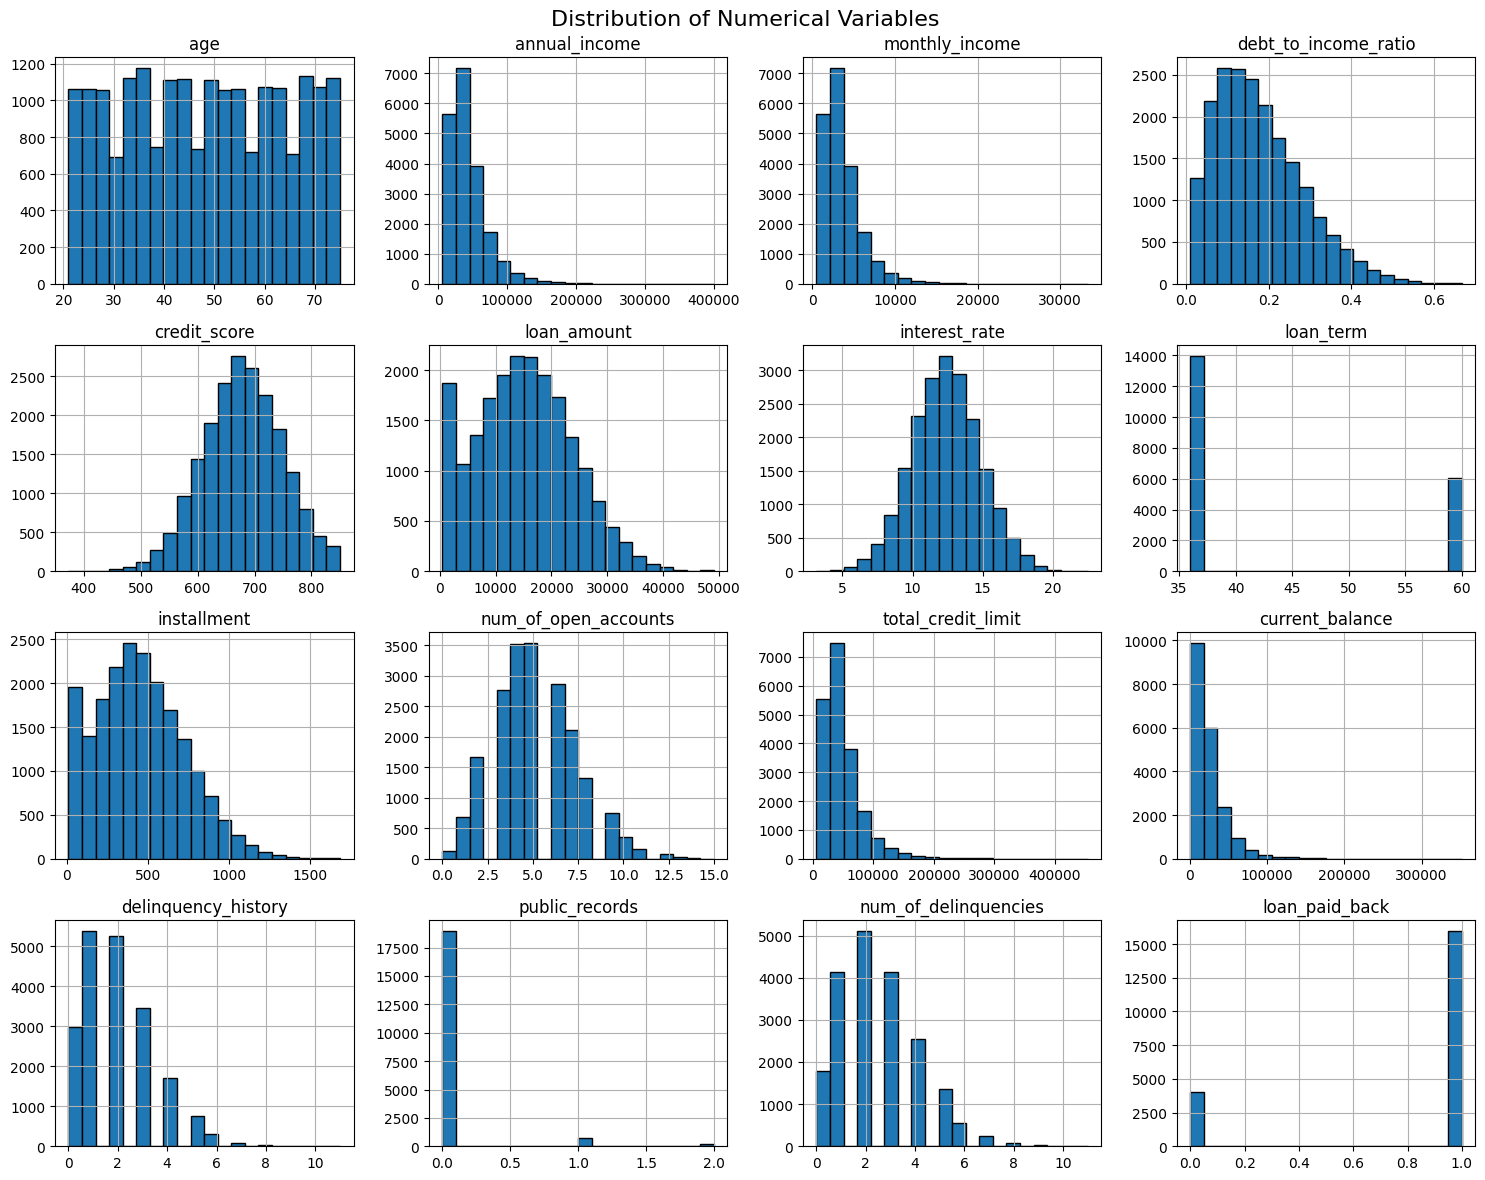

In [9]:
numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Variables", fontsize=16)
plt.tight_layout()
plt.show()

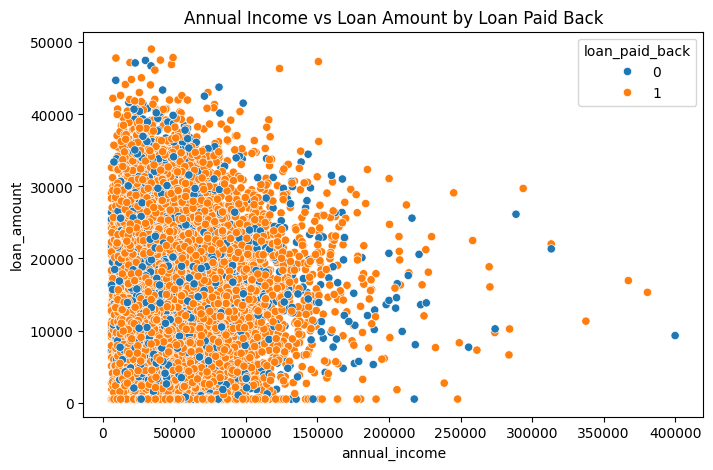

In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="annual_income",
    y="loan_amount",
    hue="loan_paid_back"
)

plt.title("Annual Income vs Loan Amount by Loan Paid Back")
plt.show()

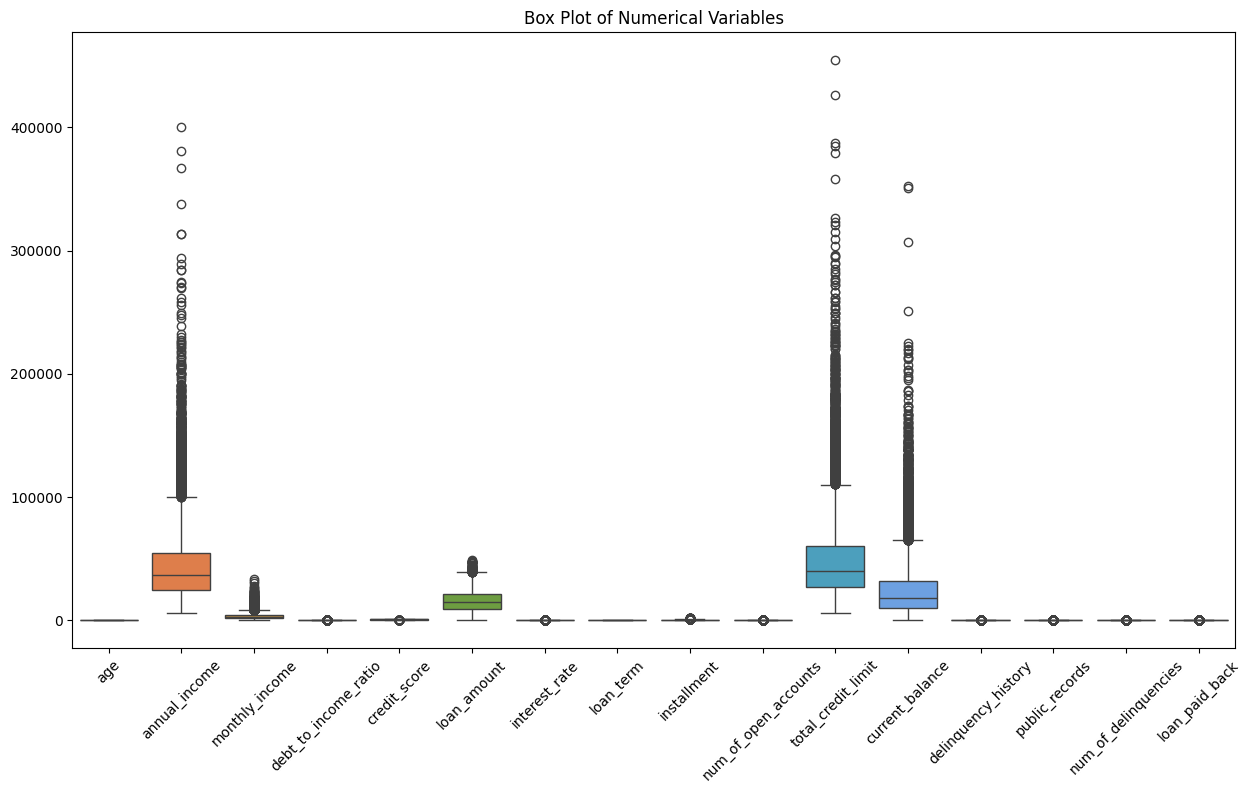

In [11]:
plt.figure(figsize=(15, 8))

sns.boxplot(data=df[numeric_cols])

plt.title("Box Plot of Numerical Variables")
plt.xticks(rotation=45)
plt.show()

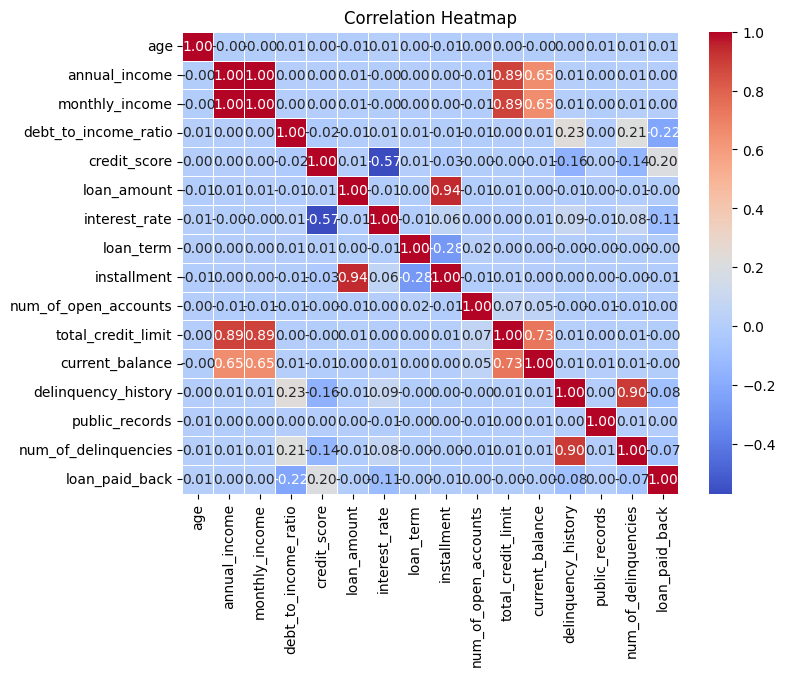

In [12]:
correlation = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

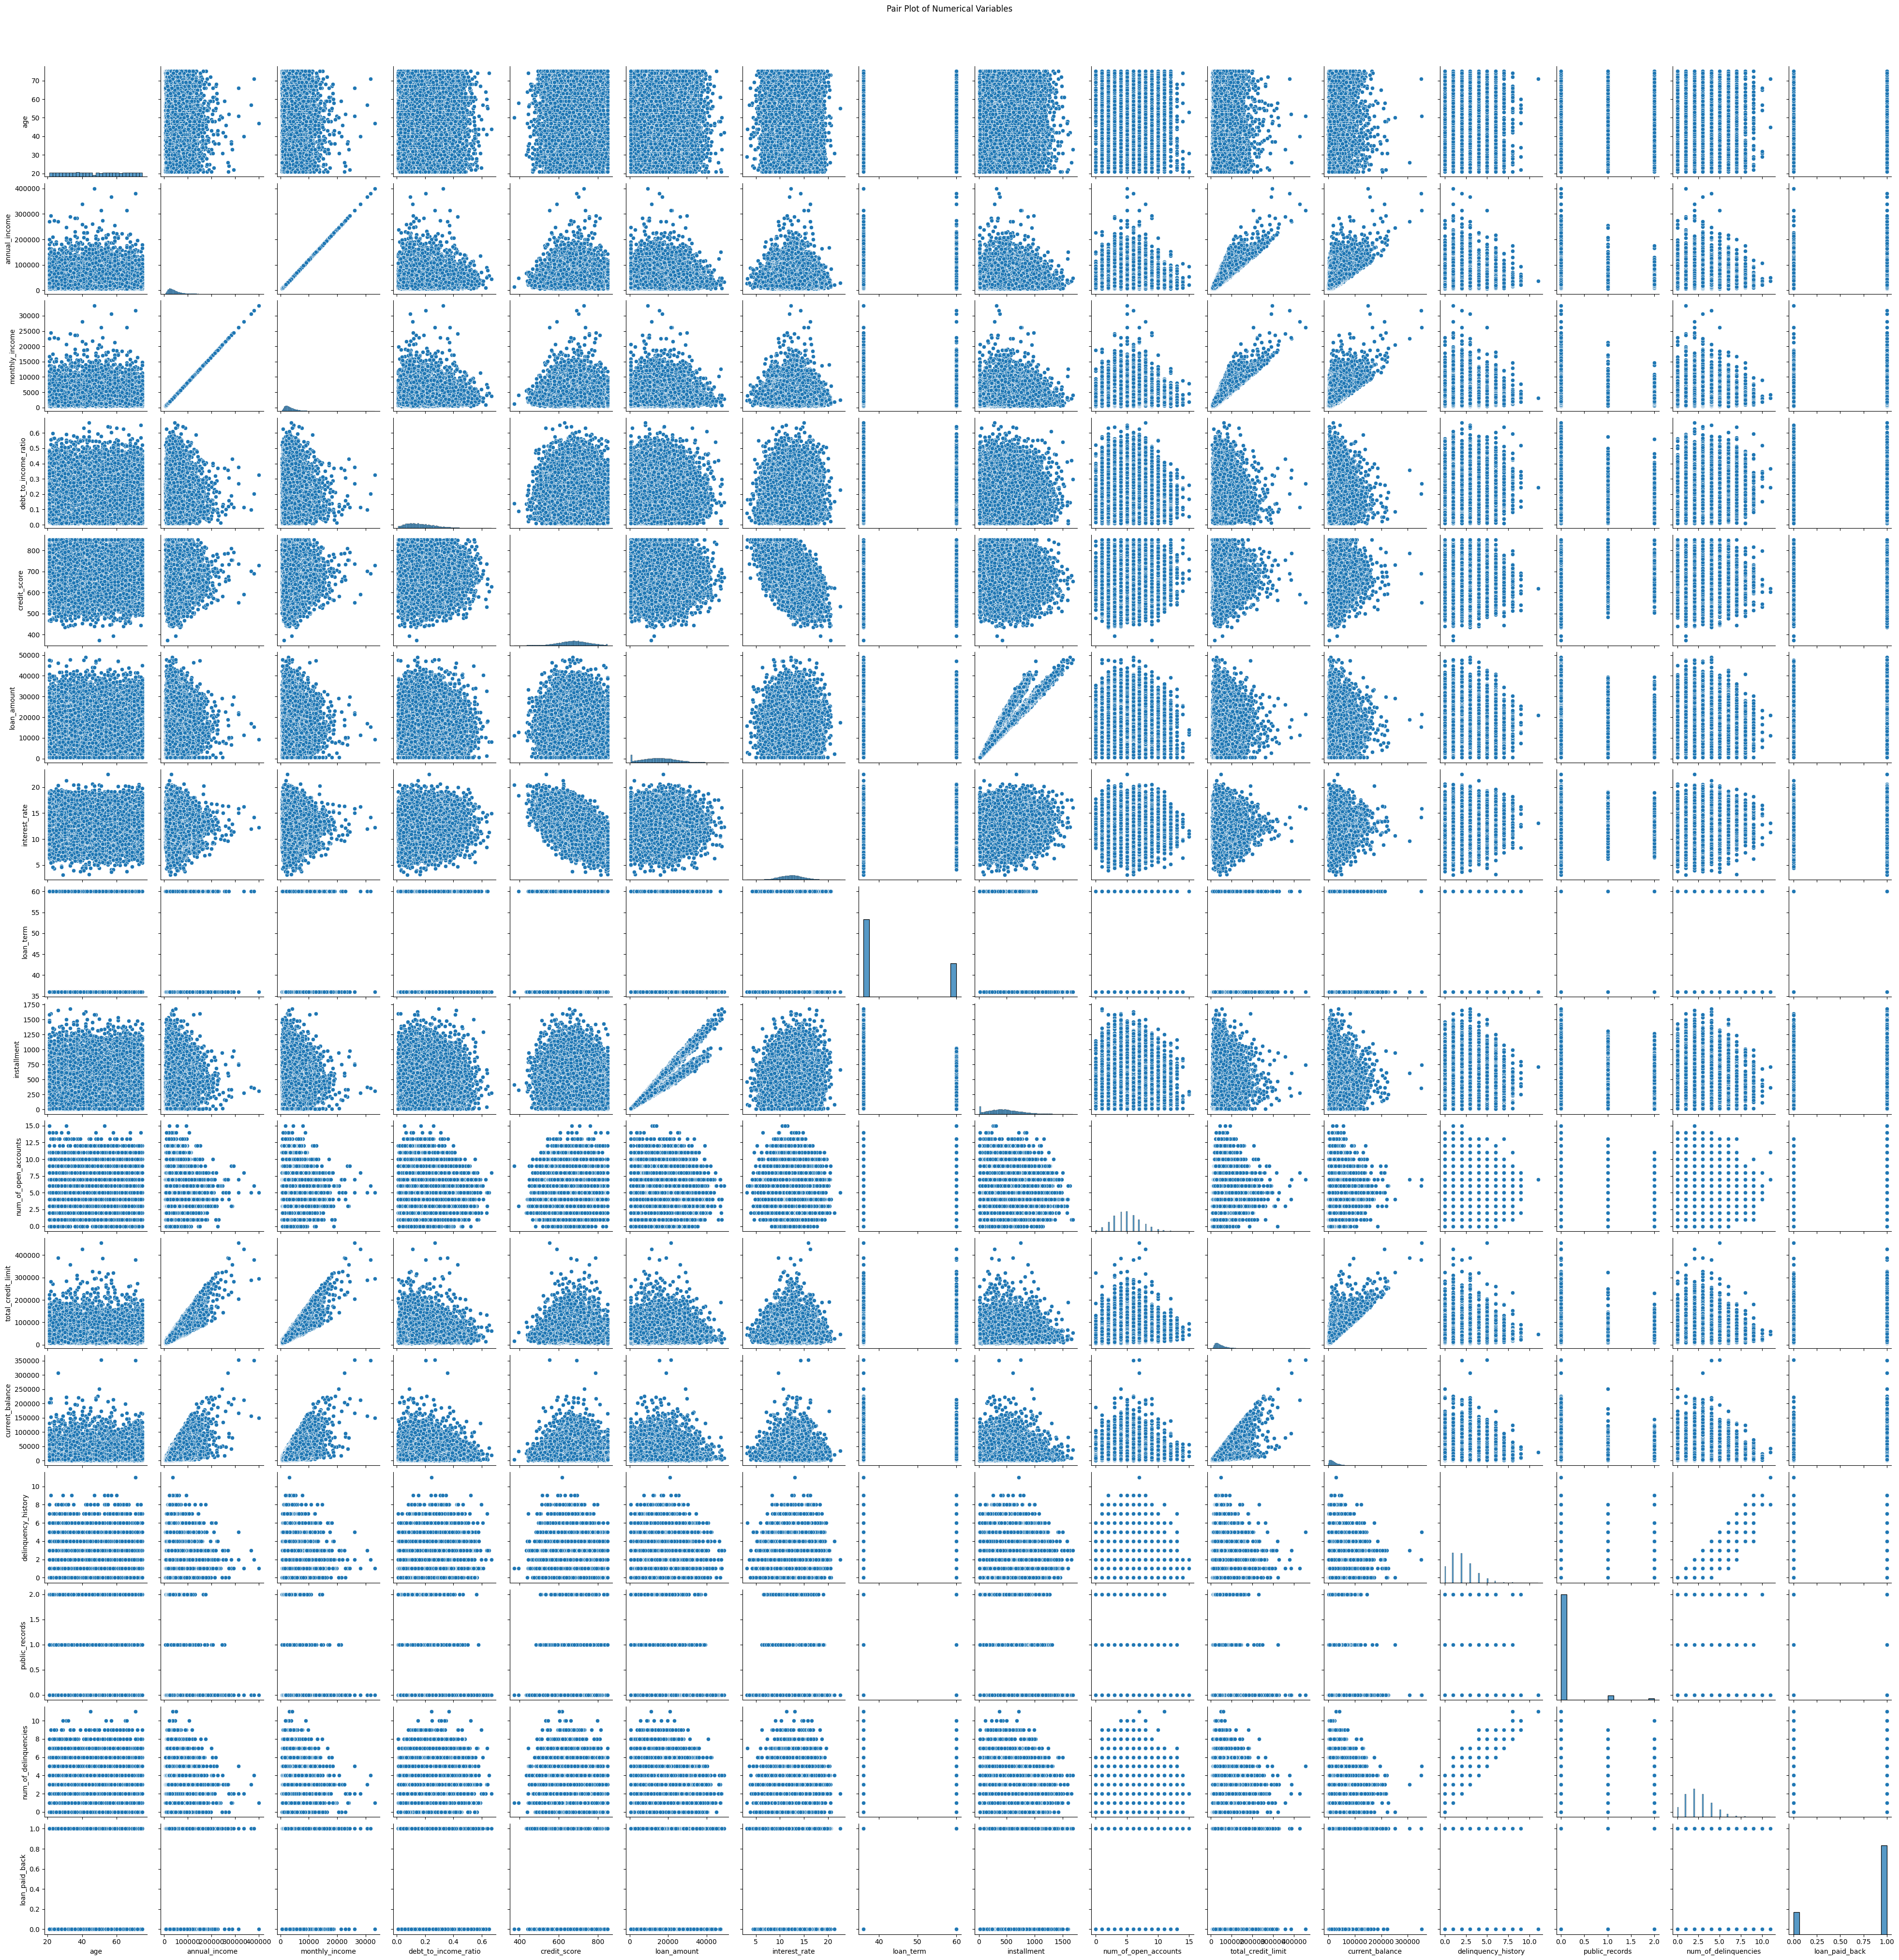

In [13]:
numeric_cols = df.select_dtypes(include=np.number).columns

sns.pairplot(
    df[numeric_cols],
    diag_kind="hist"
)

plt.suptitle("Pair Plot of Numerical Variables", y=1.02)
plt.show()

In [14]:
import pandas as pd
from sklearn.linear_model import LinearRegression

df = pd.read_csv("/kaggle/input/datasets/deeplumiere/load-pred-dataset/original_dataset.csv")

df = df[["annual_income", "loan_amount"]].dropna()

X = df[["annual_income"]]
y = df["loan_amount"]

model = LinearRegression()

model.fit(X, y)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)
print("Regression Equation:")
print("loan_amount =", model.intercept_, "+", model.coef_[0], "* annual_income")

Coefficient: 0.0015290599375373407
Intercept: 15062.710902098512
Regression Equation:
loan_amount = 15062.710902098512 + 0.0015290599375373407 * annual_income
